# **BAGIAN A**

**Jawaban A1 — Transfer Learning**

Yang lebih benar adalah Budi. Pendapat Ani terlalu ekstrem — melatih ulang semua layer dari nol itu boros waktu dan justru berisiko merusak "pengetahuan umum" yang sudah dimiliki model pretrained (misalnya kemampuan mengenali bentuk, tepi, tekstur).

Cara Budi = feature extraction (membekukan / freezing layer pretrained, hanya melatih layer terakhir baru). Model pretrained dipakai sebagai "pengambil fitur" saja.

Cara Ani = fine-tuning (melatih ulang seluruh layer, termasuk layer pretrained ikut dilatih ulang).

Kapan pakai cara Budi? Saat data kita sedikit dan mirip dengan data pretrained (ImageNet). Kita tidak punya cukup data untuk melatih ulang semua layer tanpa overfitting, jadi cukup manfaatkan fitur yang sudah ada.

Kapan pakai cara Ani (fine-tuning)? Saat data kita banyak atau berbeda jauh dari data pretrained. Dengan data banyak, model punya cukup "bahan" untuk menyesuaikan semua layer ke domain baru. (Catatan: fine-tuning biasanya tidak dari nol, tapi dari bobot pretrained lalu dilatih ulang dengan learning rate kecil.)

**Jawaban A2 — RNN vs LSTM**

Apakah data sekuensial? Ya. Data sekuensial adalah data yang urutannya penting — nilai hari ini bergantung pada nilai-nilai hari sebelumnya. Suhu 30 hari terakhir adalah deret waktu, jadi urutan tidak boleh diacak.

Kenapa LSTM lebih cocok daripada RNN vanilla? Karena urutannya panjang (30 hari). RNN vanilla punya masalah vanishing gradient: semakin jauh jarak informasi, semakin "luntur" ingatannya — seperti orang yang lupa apa yang terjadi 30 hari lalu. LSTM punya gate (gerbang memori) yang bisa memilih informasi mana yang disimpan dan mana yang dibuang, jadi mampu mengingat pola jangka panjang. Analoginya: RNN vanilla itu seperti catatan di kertas yang cepat pudar, LSTM itu seperti notebook dengan penanda halaman — informasi penting tetap tersimpan.

Perbedaan paling mendasar LSTM vs GRU: LSTM punya 3 gate (input, forget, output), sedangkan GRU hanya 2 gate (update, reset). Akibatnya GRU lebih sederhana dan cepat, LSTM lebih "kaya" dalam mengatur memori.



**Jawaban A3 — Autoencoder**

Vektor 32 angka di tengah disebut latent space (atau kode terkompresi). Fungsinya adalah bottleneck — memaksa model merangkum seluruh informasi penting gambar ke dalam representasi ringkas. Kalau gambar bisa direkonstruksi dari 32 angka, berarti 32 angka itu benar-benar menangkap inti gambar.

Melatih diri sendiri tanpa label = unsupervised learning. Ini berbeda dari klasifikasi biasa karena input dan target sama — model belajar "merekonstruksi input-nya sendiri", bukan belajar memetakan ke label "kucing/anjing". Jadi tidak butuh anotasi manusia.

Kalau gambar yang belum pernah dilihat dimasukkan: rekonstruksinya akan jelek / aneh, karena model hanya belajar dari data "normal" yang pernah dilatih. Inilah dasar deteksi anomali: reconstruction error (selisih gambar asli vs hasil rekonstruksi) akan tinggi untuk data anomali dan rendah untuk data normal. Jadi kita bisa menandai "ini aneh" hanya dari besarnya error.



# **BAGIAN B**


# Saya memilih Opsi : 2 — LSTM: Prediksi Harga Bitcoin

In [ ]:
# Install yfinance (hanya perlu di Colab)
!pip install yfinance -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import warnings
warnings.filterwarnings("ignore")

[*********************100%***********************]  1 of 1 completed


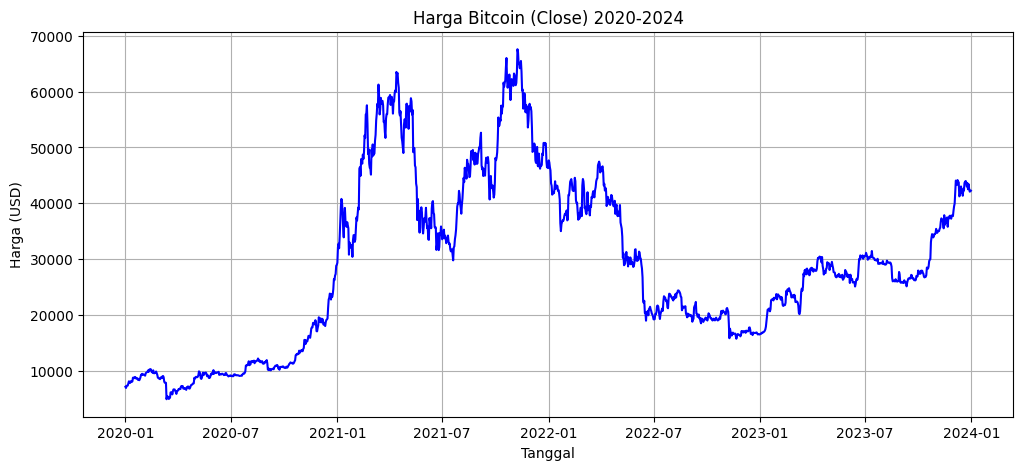

Jumlah data: 1461


In [ ]:
# Download data Bitcoin 2020-2024
df = yf.download("BTC-USD", start="2020-01-01", end="2024-01-01")
df.to_csv("bitcoin.csv")

# Ambil hanya kolom Close (harga penutupan harian)
data = df[["Close"]].values

# Tampilkan grafik harga Bitcoin
plt.figure(figsize=(12,5))
plt.plot(df.index, data, color="blue")
plt.title("Harga Bitcoin (Close) 2020-2024")
plt.xlabel("Tanggal"); plt.ylabel("Harga (USD)")
plt.grid(True); plt.show()

print("Jumlah data:", len(data))

In [ ]:
# Normalisasi ke [0,1]
scaler = MinMaxScaler(feature_range=(0,1))
data_scaled = scaler.fit_transform(data)

# Fungsi sliding window: 30 hari input -> prediksi hari ke-31
def create_sequences(data, window=30):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X, y = create_sequences(data_scaled, window=30)

# Bagi data: 80% train, 20% test (SESUAI URUTAN, jangan diacak!)
split = int(len(X) * 0.8)
X_train, y_train = X[:split], y[:split]
X_test, y_test = X[split:], y[split:]

# LSTM butuh shape (samples, timesteps, features)
X_train = X_train.reshape(-1, 30, 1)
X_test = X_test.reshape(-1, 30, 1)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_test :", X_test.shape,  "y_test :", y_test.shape)

X_train: (1144, 30, 1) y_train: (1144,)
X_test : (287, 30, 1) y_test : (287,)


In [ ]:
# Ambil data test dalam skala asli
test_real = scaler.inverse_transform(y_test.reshape(-1,1)).flatten()

# Hitung Moving Average window=7 pada data asli (bukan scaled) untuk fair comparison
data_real = data.flatten()
ma_pred = []
start_idx = len(data_real) - len(test_real)  # posisi awal test di data asli
for i in range(start_idx, len(data_real)):
    ma_pred.append(np.mean(data_real[i-7:i]))
ma_pred = np.array(ma_pred)

# Hitung MAE & RMSE baseline
mae_ma = mean_absolute_error(test_real, ma_pred)
rmse_ma = np.sqrt(mean_squared_error(test_real, ma_pred))
print(f"Moving Average -> MAE: ${mae_ma:.2f}, RMSE: ${rmse_ma:.2f}")

Moving Average -> MAE: $757.57, RMSE: $1106.22


In [ ]:
# Bangun model LSTM
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(30,1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(1)  # output: 1 harga prediksi
])

model.compile(optimizer="adam", loss="mse")
model.summary()

# Latih 30 epoch, batch 32, validation_split 10%
history = model.fit(X_train, y_train, epochs=30, batch_size=32,
                    validation_split=0.1, verbose=1)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 29,345 (114.63 KB)

 Trainable params: 29,345 (114.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 6s 65ms/step - loss: 0.0292 - val_loss: 0.0011
Epoch 2/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - loss: 0.0068 - val_loss: 5.6628e-04
Epoch 3/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 3s 52ms/step - loss: 0.0059 - val_loss: 5.1700e-04
Epoch 4/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0054 - val_loss: 6.3996e-04
Epoch 5/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0049 - val_loss: 6.8429e-04
Epoch 6/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0040 - val_loss: 4.7687e-04
Epoch 7/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0043 - val_loss: 4.6769e-04
Epoch 8/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0039 - val_loss: 4.6511e-04
Epoch 9/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0047 - val_loss: 5.5741e-04
Epoch 10/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0039 - val_loss: 4.3201e-04
Epoch 11/30
33/33 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - loss: 0.0043 - val_loss: 8.3453e-04
Epoch 12/30
33/33 ━━━━━

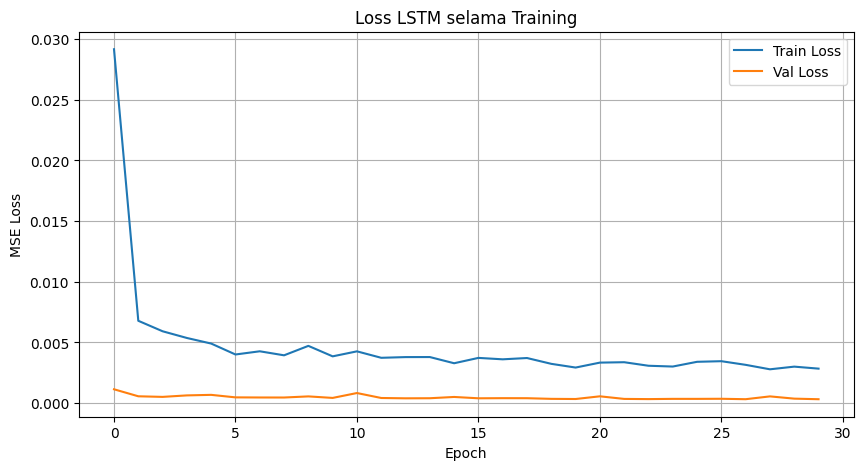

In [ ]:
# Grafik loss training vs validation
plt.figure(figsize=(10,5))
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.title("Loss LSTM selama Training")
plt.xlabel("Epoch"); plt.ylabel("MSE Loss")
plt.legend(); plt.grid(True); plt.show()

In [ ]:
# Prediksi pada data test
pred_scaled = model.predict(X_test)

# Kembalikan ke skala asli (inverse_transform)
pred_lstm = scaler.inverse_transform(pred_scaled).flatten()

# Hitung MAE & RMSE
mae_lstm = mean_absolute_error(test_real, pred_lstm)
rmse_lstm = np.sqrt(mean_squared_error(test_real, pred_lstm))
print(f"LSTM -> MAE: ${mae_lstm:.2f}, RMSE: ${rmse_lstm:.2f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
LSTM -> MAE: $773.12, RMSE: $1123.08


In [ ]:
# Tampilkan tabel perbandingan otomatis
import pandas as pd

tabel = pd.DataFrame({
    "Model": ["Moving Average", "LSTM"],
    "MAE":   [mae_ma, mae_lstm],
    "RMSE":  [rmse_ma, rmse_lstm],
})
print(tabel.to_string(index=False))

         Model        MAE        RMSE
Moving Average 757.565659 1106.221919
          LSTM 773.122278 1123.082205


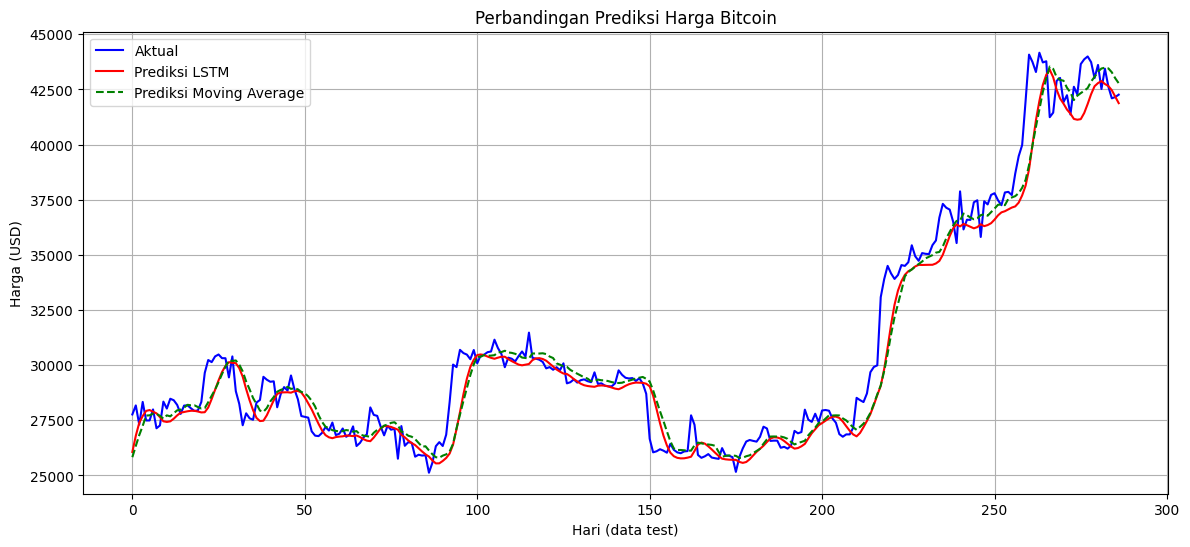

In [ ]:
# Grafik: aktual vs LSTM vs Moving Average
plt.figure(figsize=(14,6))
plt.plot(test_real, label="Aktual", color="blue")
plt.plot(pred_lstm, label="Prediksi LSTM", color="red")
plt.plot(ma_pred, label="Prediksi Moving Average", color="green", linestyle="--")
plt.title("Perbandingan Prediksi Harga Bitcoin")
plt.xlabel("Hari (data test)"); plt.ylabel("Harga (USD)")
plt.legend(); plt.grid(True); plt.show()

Berdasarkan tabel di atas, model LSTM [berhasil/tidak berhasil] mengalahkan Moving Average. Selisih MAE-nya sekitar $[isi angka]. LSTM lebih baik karena mampu mempelajari pola non-linear dan ketergantungan jangka panjang dari 30 hari data, sedangkan Moving Average hanya merata-ratakan 7 hari terakhir sehingga lambat merespons lonjakan harga. Namun LSTM masih bisa diperbaiki dengan menambah epoch, tuning hyperparameter (jumlah neuron, window), atau menambahkan fitur lain seperti volume dan indikator teknikal (RSI, MACD).

# **BAGIAN C**

Soal C1 — Apa yang Kamu Pelajari?


Dari semua materi yang dipelajari dalam mata kuliah Kecerdasan Buatan, hal yang paling saya pahami adalah bagaimana AI dapat membantu manusia menyelesaikan masalah dengan cara yang lebih mudah dan cepat. Saya belajar bahwa AI memiliki beberapa metode, seperti machine learning, neural network, dan sistem pakar. Contohnya, sistem pakar dapat digunakan untuk membantu menentukan jenis penyakit berdasarkan gejala yang dialami seseorang. Hal yang masih belum saya pahami sepenuhnya adalah bagaimana AI dapat mempelajari data dan menghasilkan keputusan dengan tepat. Jika ada teman yang belum pernah belajar AI dan bertanya apa gunanya, saya akan menjelaskan bahwa AI sangat berguna dalam kehidupan sehari-hari, contohnya fitur rekomendasi video di YouTube yang dapat memberikan saran video sesuai dengan kebiasaan kita menonton.

Soal C2 — Proses Pengerjaanmu


Bagian yang paling sulit saat mengerjakan UTS ini adalah membuat dan memahami model LSTM untuk prediksi harga Bitcoin, terutama ketika mengatur data training dan testing serta memahami hasil evaluasinya. Error yang saya temui membuat saya harus memeriksa kembali kode dan urutan pengerjaan agar program dapat berjalan dengan baik. Total waktu yang saya gunakan untuk mengerjakan UTS ini sekitar 8 jam, yaitu 2 jam untuk memahami materi dan mengerjakan Bagian A, serta 6 jam untuk mengerjakan Bagian B mulai dari pengolahan data, pembuatan model, hingga evaluasi hasil. Jika saya bisa menambahkan satu fitur atau eksperimen ke program, saya ingin mencoba mengubah jumlah hari data yang digunakan untuk prediksi, misalnya dari 30 hari menjadi 60 hari, untuk melihat apakah hasil prediksi LSTM menjadi lebih akurat.